In [25]:
import numpy as np
from scipy.sparse import csr_matrix
from scipy.sparse.csgraph import shortest_path
import matplotlib.pyplot as plt
from pathlib import Path

In [26]:
base_dir      = Path("/Users/angelaliu/Library/CloudStorage/OneDrive-MassachusettsInstituteofTechnology/Fracture Flow UROP")
transport_dir = base_dir / "Updated Code" / "transport narrowed param ranges"

In [27]:
# Python port of the fracture-network-generation pipeline in
# Updated Code/generate_fractures.m, fracture_intersections.m, build_network.m,
# backbone.m -- reimplemented here (not run through MATLAB, which isn't
# available in this environment) to actually produce and validate a labeled
# figure now, rather than write MATLAB code that can't be tested here. This is
# a faithful port of the algorithm/formulas (verified line-by-line against the
# .m files), not a bit-exact replica of any specific MATLAB seed's output --
# numpy and MATLAB use different underlying PRNGs, so this is an independent
# realization from the same distributions, which is what "a representative
# network" calls for anyway.

def generate_fractures(Lx, Ly, Nx, Ny, lx, ly, bmin, bmax, rng):
    """Port of generate_fractures.m. x-fractures ("horizontal"): midpoint
    (Uniform(0,Lx), Uniform(0,Ly)) with y-coords SORTED ascending (needed by
    build_network.m's adjacent-node link-forming assumption); length
    Uniform(0,lx), extends symmetrically in x. y-fractures ("vertical"):
    midpoint (Uniform(0,Lx) SORTED, Uniform(0,Ly)); length Uniform(0,ly),
    extends symmetrically in y. Apertures are per-fracture Uniform(bmin,bmax)."""
    xfmid = np.column_stack([rng.uniform(0, Lx, Nx), np.sort(rng.uniform(0, Ly, Nx))])
    yfmid = np.column_stack([np.sort(rng.uniform(0, Lx, Ny)), rng.uniform(0, Ly, Ny)])
    lfx = lx * rng.uniform(0, 1, Nx)
    lfy = ly * rng.uniform(0, 1, Ny)
    bfx = bmin + (bmax - bmin) * rng.uniform(0, 1, Nx)
    bfy = bmin + (bmax - bmin) * rng.uniform(0, 1, Ny)
    xfini = np.column_stack([xfmid[:, 0] - 0.5 * lfx, xfmid[:, 1]])
    xfend = np.column_stack([xfmid[:, 0] + 0.5 * lfx, xfmid[:, 1]])
    yfini = np.column_stack([yfmid[:, 0], yfmid[:, 1] - 0.5 * lfy])
    yfend = np.column_stack([yfmid[:, 0], yfmid[:, 1] + 0.5 * lfy])
    return xfmid, xfini, xfend, lfx, bfx, yfmid, yfini, yfend, lfy, bfy


def fracture_intersections(Lx, Ly, Nx, Ny, xfmid, xfini, xfend, yfmid, yfini, yfend):
    """Port of fracture_intersections.m. nfracy=0 marks a left-boundary node
    (x=0), nfracy=Ny+1 marks a right-boundary node (x=Lx); both act as
    inlet/outlet sentinels. nfracx/nfracy kept 1-indexed (MATLAB convention)
    since build_network's aperture lookups (bfx[ifracx-1] etc.) depend on it."""
    posnode, nfracx, nfracy = [], [], []
    for ix in range(Nx):
        xini, xend = xfini[ix, 0], xfend[ix, 0]
        ynode = xfmid[ix, 1]

        if xini < 0:
            for iy in range(Ny):
                xmid = yfmid[iy, 0]
                yini, yend = yfini[iy, 1], yfend[iy, 1]
                if (xmid < xend) and (ynode > yini) and (ynode < yend):
                    posnode.append([0.0, ynode]); nfracx.append(ix + 1); nfracy.append(0)
                    break

        for iy in range(Ny):
            xnode = yfmid[iy, 0]
            yini, yend = yfini[iy, 1], yfend[iy, 1]
            if (xnode > xini) and (xnode < xend) and (ynode > yini) and (ynode < yend):
                posnode.append([xnode, ynode]); nfracx.append(ix + 1); nfracy.append(iy + 1)

        if xend > Lx:
            for iy in range(Ny):
                xmid = yfmid[iy, 0]
                yini, yend = yfini[iy, 1], yfend[iy, 1]
                if (xmid > xini) and (ynode > yini) and (ynode < yend):
                    posnode.append([Lx, ynode]); nfracx.append(ix + 1); nfracy.append(Ny + 1)
                    break

    posnode = np.array(posnode)
    nfracx = np.array(nfracx)
    nfracy = np.array(nfracy)
    return posnode, nfracx, nfracy, len(posnode)


def build_network(nnode, posnode, nfracx, nfracy, Nx, Ny, bfx, bfy, visc):
    """Port of build_network.m. Relies on nodes for a given x-fracture (resp.
    y-fracture, after sorting by nfracy) being contiguous AND in ascending
    x-order (resp. y-order) -- true by construction, since x-fractures are
    generated pre-sorted by y and y-fractures pre-sorted by x (see
    generate_fractures above)."""
    linknods, linkapert, linktrans = [], [], []

    for inode in range(nnode - 1):
        ifracx = nfracx[inode]
        jnode = inode + 1
        if nfracx[jnode] == ifracx:
            linknods.append([inode, jnode])
            linkapert.append(bfx[ifracx - 1])
            linktrans.append(bfx[ifracx - 1] ** 3 / (12 * visc) / (posnode[jnode, 0] - posnode[inode, 0]))

    ids = np.argsort(nfracy, kind='stable')
    for inode in range(nnode - 1):
        ifracy = nfracy[ids[inode]]
        jnode = inode + 1
        jfracy = nfracy[ids[jnode]]
        if (jfracy == ifracy) and (1 <= ifracy <= Ny):
            i_orig, j_orig = ids[inode], ids[jnode]
            linknods.append([i_orig, j_orig])
            linkapert.append(bfy[ifracy - 1])
            linktrans.append(bfy[ifracy - 1] ** 3 / (12 * visc) / (posnode[j_orig, 1] - posnode[i_orig, 1]))

    return np.array(linknods), np.array(linkapert), np.array(linktrans), len(linknods)


def backbone(linknods, linktrans, posnode, nnode, Lx):
    """Port of backbone.m: backbone = nodes with a finite shortest-path
    distance to BOTH some inlet node (x=0) and some outlet node (x=Lx)."""
    rows = np.concatenate([linknods[:, 0], linknods[:, 1]])
    cols = np.concatenate([linknods[:, 1], linknods[:, 0]])
    data = np.concatenate([linktrans, linktrans])
    Adjmat = csr_matrix((data, (rows, cols)), shape=(nnode, nnode))

    inletnods = np.where(posnode[:, 0] == 0)[0]
    outletnods = np.where(posnode[:, 0] == Lx)[0]

    inletdist = shortest_path(Adjmat, method='D', indices=inletnods, unweighted=False, directed=False).min(axis=0)
    outletdist = shortest_path(Adjmat, method='D', indices=outletnods, unweighted=False, directed=False).min(axis=0)
    bounddist = inletdist + outletdist

    backbonenods = np.where(np.isfinite(bounddist))[0]
    isolatednods = np.where(~np.isfinite(bounddist))[0]
    return backbonenods, isolatednods, inletnods, outletnods

In [28]:
# Representative parameter set: param set 119 from the real 120-param sweep
# ("transport narrowed param ranges"), used throughout this session as a
# well-connected example (p0=0.01, i.e. 99% of trials connected).
Lx, Ly = 150.0, 50.0
d = 1.17      # discspacing
r = 0.49      # length_ratio
b = 1.53e-4   # aperture
visc = 1e-3

Nx = round(Lx / d)
Ny = round(Ly / d)
lx = r * Lx
ly = r * Ly
bmin = bmax = b

print(f"Lx={Lx}, Ly={Ly}, d={d}, r={r}, b={b:.2e}")
print(f"Nx={Nx}, Ny={Ny}, lx={lx:.1f}, ly={ly:.1f}")

Lx=150.0, Ly=50.0, d=1.17, r=0.49, b=1.53e-04
Nx=128, Ny=43, lx=73.5, ly=24.5


In [29]:
rng = np.random.default_rng(42)
xfmid, xfini, xfend, lfx, bfx, yfmid, yfini, yfend, lfy, bfy = generate_fractures(
    Lx, Ly, Nx, Ny, lx, ly, bmin, bmax, rng)
posnode, nfracx, nfracy, nnode = fracture_intersections(
    Lx, Ly, Nx, Ny, xfmid, xfini, xfend, yfmid, yfini, yfend)
linknods, linkapert, linktrans, nlink = build_network(
    nnode, posnode, nfracx, nfracy, Nx, Ny, bfx, bfy, visc)
backbonenods, isolatednods, inletnods, outletnods = backbone(
    linknods, linktrans, posnode, nnode, Lx)

print(f"nnode={nnode}, nlink={nlink}")
print(f"backbone nodes: {len(backbonenods)} / {nnode}  ({100*len(backbonenods)/nnode:.1f}%)")
print(f"inlet nodes: {len(inletnods)}, outlet nodes: {len(outletnods)}")

nnode=339, nlink=514
backbone nodes: 339 / 339  (100.0%)
inlet nodes: 15, outlet nodes: 12


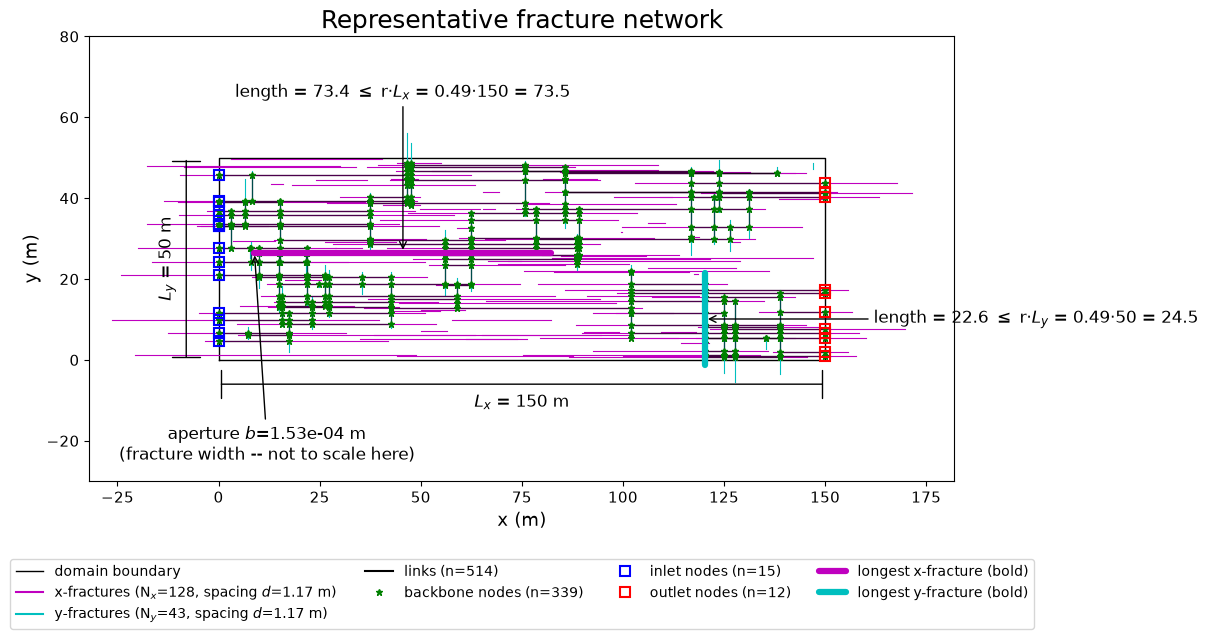

In [30]:
# Figure style mirrors the existing plot_fractures.m / plot_links.m /
# plot_backbone.m (magenta x-fractures, cyan y-fractures, black links, green
# asterisks for backbone nodes). All labeling text is placed OUTSIDE the
# domain rectangle (margins expanded accordingly) so it never overlaps the
# network itself. Lx and Ly are shown as dimension lines ("underbrace"-style)
# on the outer edges of the box instead of being spelled out in the title;
# the title itself is left bare. Nx/Ny/d (discontinuity spacing) are defined
# together in the legend. The two highlighted "longest fracture" examples are
# just bold versions of their normal color (magenta / cyan) -- no extra
# highlight color -- with plain black arrows/text pointing out to their
# length-bound labels.
i_lx = np.argmax(lfx)  # longest x-fracture
i_ly = np.argmax(lfy)  # longest y-fracture

fig, ax = plt.subplots(figsize=(12, 7))

ax.plot([0, Lx, Lx, 0, 0], [0, 0, Ly, Ly, 0], 'k-', lw=1, label='domain boundary')

ax.plot(np.column_stack([xfini[:, 0], xfend[:, 0]]).T,
        np.column_stack([xfini[:, 1], xfend[:, 1]]).T, 'm-', lw=0.8)
ax.plot(np.column_stack([yfini[:, 0], yfend[:, 0]]).T,
        np.column_stack([yfini[:, 1], yfend[:, 1]]).T, 'c-', lw=0.8)
ax.plot([], [], 'm-', lw=1.5, label=f'x-fractures (N$_x$={Nx}, spacing $d$={d:.2f} m)')
ax.plot([], [], 'c-', lw=1.5, label=f'y-fractures (N$_y$={Ny}, spacing $d$={d:.2f} m)')

for i0, i1 in linknods:
    ax.plot(posnode[[i0, i1], 0], posnode[[i0, i1], 1], 'k-', lw=1.0, alpha=0.6, zorder=2)
ax.plot([], [], 'k-', lw=1.5, label=f'links (n={nlink})')

if len(isolatednods):
    ax.plot(posnode[isolatednods, 0], posnode[isolatednods, 1], 'ko', ms=3, mfc='white',
            zorder=3, label=f'isolated nodes (n={len(isolatednods)})')
ax.plot(posnode[backbonenods, 0], posnode[backbonenods, 1], 'g*', ms=5, zorder=4,
        label=f'backbone nodes (n={len(backbonenods)})')

ax.plot(posnode[inletnods, 0], posnode[inletnods, 1], 'bs', ms=7, mfc='none', mew=1.5,
        zorder=5, label=f'inlet nodes (n={len(inletnods)})')
ax.plot(posnode[outletnods, 0], posnode[outletnods, 1], 'rs', ms=7, mfc='none', mew=1.5,
        zorder=5, label=f'outlet nodes (n={len(outletnods)})')

# --- highlight the longest x- and y-fracture: same color, just bold/wide ---
ax.plot([xfini[i_lx, 0], xfend[i_lx, 0]], [xfini[i_lx, 1], xfend[i_lx, 1]],
        color='m', lw=4.5, zorder=6, solid_capstyle='round',
        label='longest x-fracture (bold)')
ax.plot([yfini[i_ly, 0], yfend[i_ly, 0]], [yfini[i_ly, 1], yfend[i_ly, 1]],
        color='c', lw=4.5, zorder=6, solid_capstyle='round',
        label='longest y-fracture (bold)')

# labels live outside the box; arrows point back in at the fracture midpoint
ax.annotate(f'length = {lfx[i_lx]:.1f} $\\leq$ r$\\cdot L_x$ = {r:.2f}$\\cdot${Lx:.0f} = {r*Lx:.1f}',
            xy=(xfmid[i_lx, 0], xfmid[i_lx, 1]),
            xytext=(xfmid[i_lx, 0], Ly + 14),
            ha='center', va='bottom', fontsize=12, color='black', zorder=7,
            arrowprops=dict(arrowstyle='->', color='black'))

ax.annotate(f'length = {lfy[i_ly]:.1f} $\\leq$ r$\\cdot L_y$ = {r:.2f}$\\cdot${Ly:.0f} = {r*Ly:.1f}',
            xy=(yfmid[i_ly, 0], yfmid[i_ly, 1]),
            xytext=(Lx + 12, yfmid[i_ly, 1]),
            ha='left', va='center', fontsize=12, color='black', zorder=7,
            arrowprops=dict(arrowstyle='->', color='black'))

# --- aperture callout: anchored directly below the highlighted x-fracture's
# left end (short vertical arrow, not a cross-plot diagonal); label sits
# below the box (not to scale: b ~1e-4 m vs domain ~1e2 m) ---
apx = np.clip(xfini[i_lx, 0], 12, Lx - 12)
ax.annotate(f'aperture $b$={b:.2e} m\n(fracture width -- not to scale here)',
            xy=(xfini[i_lx, 0], xfini[i_lx, 1]),
            xytext=(apx, -16),
            ha='center', va='top', fontsize=12, color='black', zorder=7,
            arrowprops=dict(arrowstyle='->', color='black'))


def dim_line_horizontal(ax, x0, x1, y, label):
    """Dimension-line ('underbrace'-style) span along a horizontal edge."""
    ax.annotate('', xy=(x0, y), xytext=(x1, y),
                arrowprops=dict(arrowstyle='|-|', color='black', lw=1))
    ax.text((x0 + x1) / 2, y - 2.5, label, ha='center', va='top', fontsize=12)


def dim_line_vertical(ax, y0, y1, x, label):
    """Dimension-line ('underbrace'-style) span along a vertical edge."""
    ax.annotate('', xy=(x, y0), xytext=(x, y1),
                arrowprops=dict(arrowstyle='|-|', color='black', lw=1))
    ax.text(x - 2.5, (y0 + y1) / 2, label, ha='right', va='center', fontsize=12, rotation=90)


dim_line_horizontal(ax, 0, Lx, -6, f'$L_x$ = {Lx:.0f} m')
dim_line_vertical(ax, 0, Ly, -8, f'$L_y$ = {Ly:.0f} m')

ax.set_xlabel('x (m)', fontsize=13)
ax.set_ylabel('y (m)', fontsize=13)
# Symmetric margins (using the larger of the two label-driven margins that
# were previously asymmetric on each axis: x had -20/+32, y had -30/+22) so
# the Lx x Ly domain box sits centered within the plotted extent, not off
# to one side, while still leaving enough room for all the outside labels.
MARGIN_X = 32
MARGIN_Y = 30
ax.set_xlim(-MARGIN_X, Lx + MARGIN_X)
ax.set_ylim(-MARGIN_Y, Ly + MARGIN_Y)
ax.set_aspect('equal')
ax.set_title('Representative fracture network', fontsize=18)
ax.tick_params(labelsize=11)
ax.legend(fontsize=10, loc='upper center', bbox_to_anchor=(0.5, -0.16), ncol=4)
plt.tight_layout()
plt.savefig(transport_dir / 'representative_fracture_network.png', dpi=150, bbox_inches='tight')
plt.show()